# Regular experiments: layered vs. looped transformers

In [1]:
# Figure 2 depth/loop experiment (baseline and shared-weight looped transformer)

import torch
from matplotlib import pyplot as plt
import os
import numpy as np

from linear_transformer import generate_data, DataMode
from experiments_helper import (
    build_transformer,
    clip_and_step,
    run_experiment_suite,
    compute_loss_dict,
    compute_looped_loss_by_loop_count,
    compute_dist_identity,
    compute_dist_dict,
    compute_data_condition_numbers,
    plot_loss_curves,
    plot_parameter_matrices,
    plot_dist_to_identity,
    plot_loop_loss_curves,
)

np.set_printoptions(precision=2, suppress=True)
torch.set_printoptions(precision=2)

log_dir = 'log'
cur_dir = log_dir
os.makedirs(cur_dir, exist_ok=True)

In [2]:
# Problem parameters (defined in experiments_helper.py; edit them there so the
# helper functions see the same values)

from experiments_helper import (
    device, lr, clip_r, alg, normal_data_mode, N, d, n_head, B, var,
    max_iters, hist_stride, stride, TEST_SEED,
)

print(f'Running on device: {device}.')

Running on device: cuda.


In [3]:
####################################
# Train layered and shared-weight looped transformers
####################################

filename_format = '/figure_two_layers_vs_loops_{}_{}.pth'
filename = cur_dir + filename_format.format(N, d)

In [ ]:
seeds = [0, 1, 2]
n_layers_loops = [1, 2, 5, 10]
model_types = ['layered', 'looped']

hist_dict = run_experiment_suite(seeds, n_layers_loops, model_types, filename)

Run 1/6: seed=0, count=10, type=layered, N=10, mode=DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), heads=1, attention=linear
iter 0 | Loss: 5.7650909423828125 | time: 0.024388551712036133 | gradnorm: 13.615009307861328
iter 1 | Loss: 5.322114944458008 | time: 0.02575087547302246 | gradnorm: 12.686443328857422
iter 2 | Loss: 5.527280807495117 | time: 0.025564193725585938 | gradnorm: 12.562421798706055
iter 3 | Loss: 5.178330421447754 | time: 0.02658820152282715 | gradnorm: 12.374987602233887
iter 4 | Loss: 5.132678031921387 | time: 0.0270998477935791 | gradnorm: 12.4869384765625
iter 100 | Loss: 1.1558091640472412 | time: 0.016992807388305664 | gradnorm: 1.4975494146347046
iter 200 | Loss: 0.5305713415145874 | time: 0.02142167091369629 | gradnorm: 2.4775853157043457
[DEBUG] [Norm]: infinite gradient norm at iteration 277.


KeyboardInterrupt: 

In [7]:
loss_dict = compute_loss_dict(hist_dict, test_seed=TEST_SEED)

(0, 2, 'layered', 10, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 1)
Testing model: seed=0, count=2, type=layered, N=10, train data=DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), heads=1, attention=linear
(0, 2, 'looped', 10, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 1)
Testing model: seed=0, count=2, type=looped, N=10, train data=DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), heads=1, attention=linear
(0, 5, 'layered', 10, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 1)
Testing model: seed=0, count=5, type=layered, N=10, train data=DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), heads=1, attention=linear
(0, 5, 'looped', 10, DataMode(name='normal', gamma_shape=None, gamma_scale=None, t_degrees_freedom=None), 1)
Testing model: seed=0, count=5, type=loop

In [8]:
####################################
# integrated test-loss comparison: layered vs shared-weight looped
####################################

fig_dir = 'figures'
os.makedirs(fig_dir, exist_ok=True)
iterations = np.arange(0, max_iters, stride)

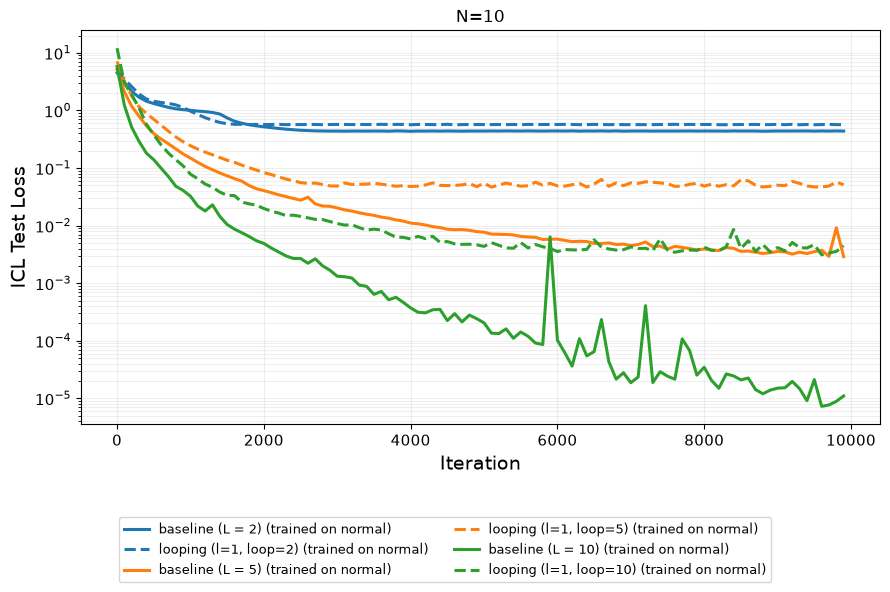

In [9]:
plot_loss_curves(loss_dict, n_layers_loops, ['layered', 'looped'], iterations, fig_dir=fig_dir)

In [ ]:
plot_parameter_matrices(hist_dict, seeds[0], n_layers_loops, model_types, n_head,
                        hist_stride=hist_stride, fig_dir=fig_dir)

In [38]:
iterations = np.arange(0, max_iters, stride)
dist_dict = compute_dist_dict(hist_dict, iterations, n_head, hist_stride=hist_stride)

NameError: name 'hist_dict' is not defined

In [37]:
plot_dist_to_identity(dist_dict, n_layers_loops, iterations, fig_dir=fig_dir)

NameError: name 'dist_dict' is not defined